<a href="https://colab.research.google.com/github/THE5NEON/Python-Labs/blob/main/%D0%9B%D0%A09_%D0%A2%D0%BE%D1%87%D0%B5%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 9
## Рекомендаційні системи: SVD та KNNBasic

**ПІБ студента:** Точенюк Ярослав  
**Група:** 4-9  
**Дата:** 24.11.2026

**Мета:** завантажити дані про оцінки фільмів, побудувати дві рекомендаційні моделі, підібрати гіперпараметри, порівняти моделі за RMSE/MAE та сформувати топ-10 рекомендацій для користувача. Додатково реалізувати власний рекомендаційний алгоритм з нуля.

**Дані:** вбудований набір MovieLens 100K (`ml-100k`) із бібліотеки Surprise.

**Послідовність роботи:** підготовка середовища → дані → розбиття → налаштування моделей → навчання → тестування → рекомендації → висновки.

## 1. Підготовка середовища

Комбінація бібліотек для **Google Colab із Python 3.13**. Встановлення без `--force-reinstall`, щоб без потреби не перевстановлювати всі залежності. Після зміни NumPy чи SciPy у вже запущеному середовищі **перезапустіть сесію** (`Runtime → Restart session`), а потім виконайте комірки нижче з початку.

In [1]:
%pip install -q \
    numpy==2.2.6 \
    scipy==1.15.3 \
    scikit-learn==1.6.1 \
    pandas==2.2.3 \
    scikit-surprise==1.1.5

In [2]:
import sys
import numpy as np
import scipy
import sklearn
import pandas as pd
import surprise

from surprise import Dataset, Reader, SVD, KNNBasic, accuracy
from surprise.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split as sklearn_train_test_split

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)
print('Surprise:', surprise.__version__)
from IPython.display import display, Markdown
from surprise.model_selection import KFold
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request
import zipfile
import io

Python: 3.13.18
NumPy: 2.4.6
SciPy: 1.15.3
scikit-learn: 1.6.1
pandas: 2.2.3
Surprise: 1.1.5


## 2. Завантаження та первинний аналіз даних

1. Завантажте вбудований набір `ml-100k`.
2. Перетворіть оцінки у `pandas.DataFrame` з колонками `user_id`, `item_id`, `rating`, `timestamp`.
3. Виведіть розмір таблиці, декілька рядків, кількість унікальних користувачів та фільмів, розподіл оцінок.

**Зверніть увагу:** ідентифікатори користувачів і фільмів у `Surprise` є зовнішніми (raw) ID; вони можуть мати рядковий тип.

In [3]:
try:
    data = Dataset.load_builtin('ml-100k', prompt=False)
except (OSError, ValueError, EOFError, zipfile.BadZipFile) as exc:
    print('Вбудоване завантаження не вдалося; використовую офіційний HTTPS-архів:', exc)
    url = 'https://files.grouplens.org/datasets/movielens/ml-100k.zip'
    with urllib.request.urlopen(url, timeout=90) as response:
        archive = response.read()
    with zipfile.ZipFile(io.BytesIO(archive)) as z:
        path = Path('ml-100k-u.data')
        path.write_bytes(z.read('ml-100k/u.data'))
    data = Dataset.load_from_file(str(path), Reader(line_format='user item rating timestamp', sep='\t', rating_scale=(1, 5)))
ratings_df = pd.DataFrame(data.raw_ratings, columns=['user_id', 'item_id', 'rating', 'timestamp'])
ratings_df['user_id'] = ratings_df['user_id'].astype(str)
ratings_df['item_id'] = ratings_df['item_id'].astype(str)
print('Розмір:', ratings_df.shape)
display(ratings_df.head())
assert not ratings_df[['user_id', 'item_id', 'rating']].isna().any().any()
assert ratings_df['rating'].between(1, 5).all()
assert len(ratings_df) == 100_000, 'Очікується повний набір MovieLens 100K'

Trying to download dataset from https://files.grouplens.org/datasets/movielens/ml-100k.zip...
Done! Dataset ml-100k has been saved to /root/.surprise_data/ml-100k
Розмір: (100000, 4)


,user_id,item_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


Користувачів: 943
Фільмів: 1682
Мінімальна оцінка: 1.0
Максимальна оцінка: 5.0
Середня оцінка: 3.5299
Пропущені значення:


,Кількість
user_id,0
item_id,0
rating,0
timestamp,0


,Кількість
rating,
1.0,6110
2.0,11370
3.0,27145
4.0,34174
5.0,21201


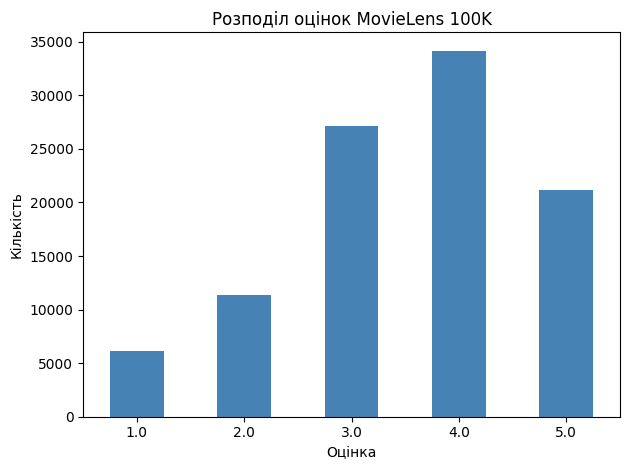

**Спостереження.** У наборі 943 користувачів та 1682 фільмів. Оцінки лежать у межах 1–5, середня оцінка становить 3.530. Найчастіше зустрічається оцінка 4; кількість пропусків — 0.

In [4]:
n_users = ratings_df.user_id.nunique()
n_items = ratings_df.item_id.nunique()
print('Користувачів:', n_users)
print('Фільмів:', n_items)
print('Мінімальна оцінка:', ratings_df.rating.min())
print('Максимальна оцінка:', ratings_df.rating.max())
print('Середня оцінка:', round(ratings_df.rating.mean(), 4))
print('Пропущені значення:')
display(ratings_df.isna().sum().to_frame('Кількість'))
counts = ratings_df.rating.value_counts().sort_index()
display(counts.to_frame('Кількість'))
ax = counts.plot.bar(color='steelblue', title='Розподіл оцінок MovieLens 100K', rot=0)
ax.set(xlabel='Оцінка', ylabel='Кількість'); plt.tight_layout(); plt.show()
display(Markdown(f'**Спостереження.** У наборі {n_users} користувачів та {n_items} фільмів. '
                 f'Оцінки лежать у межах {ratings_df.rating.min():g}–{ratings_df.rating.max():g}, '
                 f'середня оцінка становить {ratings_df.rating.mean():.3f}. '
                 f'Найчастіше зустрічається оцінка {counts.idxmax():g}; '
                 f'кількість пропусків — {int(ratings_df.isna().sum().sum())}.'))

**Короткі спостереження щодо даних:** наведено під таблицею та графіком у попередній комірці. Вони обчислюються безпосередньо з завантажених даних.

## 3. Розбиття на навчальну та тестову вибірки

Виконайте випадкове розбиття **80% / 20%** із `random_state=42` за прикладом. Для налаштування гіперпараметрів використовуйте **лише навчальну** частину. Тестова вибірка має залишатися недоторканою до фінальної оцінки.

In [5]:
train_df, test_df = sklearn_train_test_split(ratings_df, test_size=0.2, random_state=42)
assert set(train_df.index).isdisjoint(test_df.index)
assert len(train_df) + len(test_df) == len(ratings_df)
print(f'Навчальна вибірка: {len(train_df)}; тестова: {len(test_df)}')

Навчальна вибірка: 80000; тестова: 20000


In [6]:
reader = Reader(rating_scale=data.reader.rating_scale)
train_data = Dataset.load_from_df(train_df[['user_id', 'item_id', 'rating']], reader)
testset = list(test_df[['user_id', 'item_id', 'rating']].itertuples(index=False, name=None))
assert len(train_data.raw_ratings) == len(train_df)
assert len(testset) == len(test_df)
print('Train:', len(train_data.raw_ratings), '| Test:', len(testset))

Train: 80000 | Test: 20000


## 4. Гіперпараметри моделей

Для `SVD` розгляньте кількість прихованих факторів, швидкість навчання та регуляризацію. Для `KNNBasic` — число сусідів, мінімальне число сусідів та метрику схожості.

Нижче — **початкова сітка** з аналізованого прикладу. Її можна змінити й обґрунтувати вибір.

In [7]:
param_grid_svd = {
    'n_factors': [50, 100],
    'lr_all': [0.005, 0.010],
    'reg_all': [0.02, 0.05]
}

param_grid_knn = {
    'k': [20, 40],
    'min_k': [1, 5],
    'sim_options': {
        'name': ['cosine', 'pearson'],
        'user_based': [False, True]
    }
}

**Обґрунтування вибору параметрів:**

- `n_factors` (50, 100) визначає складність представлення користувачів і фільмів. Більше факторів може покращити точність, але збільшує ризик перенавчання.
- `lr_all` (0.005, 0.010) визначає швидкість оновлення параметрів, а `reg_all` (0.02, 0.05) — силу регуляризації.
- `k` (20, 40) визначає максимальну кількість сусідів, `min_k` (1, 5) — мінімальну кількість для прогнозу.
- Косинусна схожість порівнює напрямки векторів оцінок, а Pearson — кореляцію зі спільними оцінками. `user_based` дозволяє порівняти підхід за користувачами і за фільмами.

Залишаємо початкову сітку шаблону (8 комбінацій SVD, 16 KNNBasic). Для SVD фіксуємо `random_state=42`, для обох пошуків використовуємо однакові три фолди. Обмежуємо паралельність двома процесами, щоб не перевантажувати пам’ять Colab.

## 5. Пошук найкращих гіперпараметрів (GridSearchCV)

Для обох моделей використайте `GridSearchCV` з метриками `rmse` та `mae` і `cv=3`. Навчайте об’єкти пошуку **лише на `train_data`**.

In [8]:
cv = KFold(n_splits=3, random_state=42, shuffle=True)
param_grid_svd['random_state'] = [42]
grid_search_svd = GridSearchCV(SVD, param_grid_svd, measures=['rmse', 'mae'], cv=cv, n_jobs=2)
grid_search_svd.fit(train_data)
print('SVD: пошук завершено')

SVD: пошук завершено


In [9]:
param_grid_knn['verbose'] = [False]
grid_search_knn = GridSearchCV(KNNBasic, param_grid_knn, measures=['rmse', 'mae'], cv=cv, n_jobs=2)
grid_search_knn.fit(train_data)
print('KNNBasic: пошук завершено')

KNNBasic: пошук завершено


In [10]:
searches = {'SVD': grid_search_svd, 'KNNBasic': grid_search_knn}
cv_rows = []
for name, search in searches.items():
    idx = search.best_index['rmse']
    cv_rows.append({'Model': name, 'CV RMSE': search.best_score['rmse'],
                    'CV MAE (за RMSE)': search.cv_results['mean_test_mae'][idx],
                    'Best CV MAE': search.best_score['mae'],
                    'Best params (RMSE)': search.best_params['rmse']})
    print(name, '| Найкращі параметри за MAE:', search.best_params['mae'])
cv_results = pd.DataFrame(cv_rows).sort_values('CV RMSE').reset_index(drop=True)
display(cv_results)
best_name = cv_results.loc[0, 'Model']
display(Markdown(f'За кросвалідацією обрано **{best_name}**, оскільки модель має менший CV RMSE '
                 f'({cv_results.loc[0, "CV RMSE"]:.4f} проти {cv_results.loc[1, "CV RMSE"]:.4f}). '
                 'У таблиці окремо показано MAE тієї самої конфігурації та найменший MAE по всій сітці.'))

SVD | Найкращі параметри за MAE: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}
KNNBasic | Найкращі параметри за MAE: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}


,Model,CV RMSE,CV MAE (за RMSE),Best CV MAE,Best params (RMSE)
0,SVD,0.942506,0.744138,0.744138,"{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0..."
1,KNNBasic,1.027193,0.814330,0.814330,"{'k': 40, 'min_k': 1, 'sim_options': {'name': ..."


За кросвалідацією обрано **SVD**, оскільки модель має менший CV RMSE (0.9425 проти 1.0272). У таблиці окремо показано MAE тієї самої конфігурації та найменший MAE по всій сітці.

**Аналіз результатів кросвалідації:** фактичну таблицю, оптимальні параметри обох моделей та порівняння автоматично виводить попередня комірка. Вибір моделі здійснюється за CV RMSE, а не за тестовими даними.

## 6. Навчання остаточних моделей

Побудуйте `trainset = train_data.build_full_trainset()`. Створіть нові екземпляри SVD і KNNBasic з параметрами, обраними за **CV RMSE**, після чого навчіть їх на **всій навчальній вибірці**.

In [11]:
best_svd_params = dict(grid_search_svd.best_params['rmse'])
best_knn_params = dict(grid_search_knn.best_params['rmse'])
trainset = train_data.build_full_trainset()
assert trainset.n_ratings == len(train_df)
best_svd_params['random_state'] = 42
best_svd = SVD(**best_svd_params).fit(trainset)
best_knn = KNNBasic(**best_knn_params).fit(trainset)
print('SVD:', best_svd_params)
print('KNNBasic:', best_knn_params)
print('Кількість навчальних оцінок:', trainset.n_ratings)

SVD: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}
KNNBasic: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}
Кількість навчальних оцінок: 80000


## 7. Оцінювання на незалежній тестовій вибірці

Отримайте передбачення для `testset` методами `.test()` обох моделей. Обчисліть `RMSE` та `MAE` за допомогою `surprise.accuracy`.

**Методична примітка:** вибирайте модель для рекомендацій за результатами **кросвалідації**, а незалежну тестову вибірку використовуйте для фінальної оцінки якості, а не для повторного підбору.

In [12]:
svd_predictions = best_svd.test(testset)
knn_predictions = best_knn.test(testset)
assert len(svd_predictions) == len(knn_predictions) == len(testset)
svd_rmse = accuracy.rmse(svd_predictions, verbose=False)
svd_mae = accuracy.mae(svd_predictions, verbose=False)
knn_rmse = accuracy.rmse(knn_predictions, verbose=False)
knn_mae = accuracy.mae(knn_predictions, verbose=False)

,Model,RMSE,MAE
0,SVD,0.919175,0.723355
1,KNNBasic,1.011953,0.798421


,Model,CV RMSE,CV MAE (за RMSE),RMSE,MAE,Test − CV RMSE,Test − CV MAE
0,SVD,0.942506,0.744138,0.919175,0.723355,-0.023332,-0.020783
1,KNNBasic,1.027193,0.814330,1.011953,0.798421,-0.015241,-0.015909


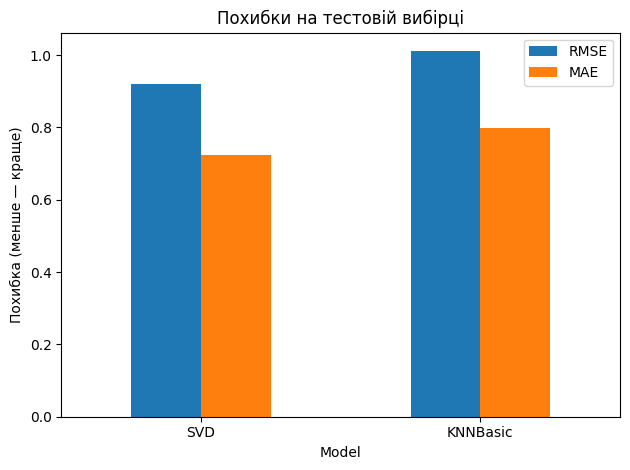

SVD: зміна RMSE -0.0233, зміна MAE -0.0208
KNNBasic: зміна RMSE -0.0152, зміна MAE -0.0159


In [13]:
results = pd.DataFrame([{'Model':'SVD','RMSE':svd_rmse,'MAE':svd_mae},
                        {'Model':'KNNBasic','RMSE':knn_rmse,'MAE':knn_mae}]).sort_values('RMSE').reset_index(drop=True)
display(results)
comparison = cv_results[['Model','CV RMSE','CV MAE (за RMSE)']].merge(results, on='Model')
comparison['Test − CV RMSE'] = comparison.RMSE - comparison['CV RMSE']
comparison['Test − CV MAE'] = comparison.MAE - comparison['CV MAE (за RMSE)']
display(comparison)
ax = results.set_index('Model')[['RMSE','MAE']].plot.bar(rot=0, title='Похибки на тестовій вибірці')
ax.set_ylabel('Похибка (менше — краще)'); plt.tight_layout(); plt.show()
for _, row in comparison.iterrows():
    print(f'{row.Model}: зміна RMSE {row["Test − CV RMSE"]:+.4f}, зміна MAE {row["Test − CV MAE"]:+.4f}')

**Таблиця тестових результатів і порівняння з CV** наведені вище. Додатна різниця означає більшу похибку на тесті, від’ємна — меншу. Величини різниць наведено чисельно; без окремої оцінки статистичної невизначеності не стверджуємо, що вони статистично значущі.

## 8. Топ-10 рекомендацій для користувача

1. Оберіть модель із кращим **CV RMSE**.
2. Задайте `user_id` (вихідний приклад використовує `'196'`).
3. Отримайте фільми, які цей користувач уже оцінив у навчальній вибірці.
4. Для решти фільмів обчисліть прогнозований рейтинг `.predict(uid=..., iid=...).est`.
5. Виведіть **10 фільмів із найбільшим прогнозованим рейтингом**.

**Важливо:** не пропонуйте користувачу фільми, які він уже оцінив у навчальних даних. Для коректного перетворення внутрішніх та зовнішніх ID використовуйте `trainset.to_inner_uid()`, `trainset.to_raw_iid()`.

In [14]:
user_id = '196'
selected_model = {'SVD': best_svd, 'KNNBasic': best_knn}[best_name]
print('Модель за CV RMSE:', best_name)
def recommend_surprise(model, user_id, n=10):
    user_id = str(user_id)
    try:
        inner_uid = model.trainset.to_inner_uid(user_id)
    except ValueError:
        print(f'Користувач {user_id} відсутній у навчальній вибірці. Оберіть відомий ID.')
        return pd.DataFrame(columns=['item_id','predicted_rating'])
    rated = {iid for iid, _ in model.trainset.ur[inner_uid]}
    candidates = [model.trainset.to_raw_iid(iid) for iid in model.trainset.all_items() if iid not in rated]
    rows = [(iid, model.predict(uid=user_id, iid=iid).est) for iid in candidates]
    return (pd.DataFrame(rows, columns=['item_id','predicted_rating'])
            .sort_values(['predicted_rating','item_id'], ascending=[False,True]).head(n).reset_index(drop=True))
top10 = recommend_surprise(selected_model, user_id)
display(top10)
seen = set(train_df.loc[train_df.user_id == user_id, 'item_id'])
assert set(top10.item_id).isdisjoint(seen)
assert top10.item_id.is_unique
assert top10.predicted_rating.between(*reader.rating_scale).all()
assert len(top10) <= 10
if len(top10):
    assert top10.predicted_rating.is_monotonic_decreasing
    print('Перевірка: уже оцінені фільми не потрапили до рекомендацій.')

Модель за CV RMSE: SVD


,item_id,predicted_rating
0,320,4.490358
1,64,4.470680
2,480,4.413710
3,313,4.401920
4,513,4.399624
5,483,4.398092
6,318,4.392102
7,656,4.385379
8,22,4.377388
9,272,4.376010


Перевірка: уже оцінені фільми не потрапили до рекомендацій.


## 9. Перевірка виконання

Автоматичні перевірки розміру та діапазону оцінок, неперетинності вибірок, кількості прогнозів і виключення оцінених фільмів містяться в програмних комірках. Фактичний запуск у Colab необхідний для підтвердження повного виконання.

## 10. Висновки

Нижче висновок генерується на основі фактичних результатів навчання, а не наперед заданих метрик.

In [15]:
s = comparison.set_index('Model')
chosen = s.loc[best_name]
other_name = next(name for name in searches if name != best_name)
other = s.loc[other_name]
display(Markdown(
    f'1. За кросвалідацією обрано **{best_name}**, CV RMSE = {chosen["CV RMSE"]:.4f}, '
    f'тоді як для {other_name} він становить {other["CV RMSE"]:.4f}.\n'
    f'2. Найкращі параметри SVD: `{best_svd_params}`.\n'
    f'3. Найкращі параметри KNNBasic: `{best_knn_params}`.\n'
    f'4. На незалежній вибірці SVD отримала RMSE = {svd_rmse:.4f}, MAE = {svd_mae:.4f}, '
    f'а KNNBasic — RMSE = {knn_rmse:.4f}, MAE = {knn_mae:.4f}.\n'
    f'5. Для обраної моделі різниця Test − CV RMSE становить {chosen["Test − CV RMSE"]:+.4f}, '
    f'а MAE — {chosen["Test − CV MAE"]:+.4f}.\n'
    f'6. Для користувача {user_id} отримано {len(top10)} рекомендацій серед фільмів, '
    'які він не оцінював у навчальній вибірці.\n'
    '7. Обмеження системи — холодний старт для нових користувачів/фільмів, розрідженість оцінок '
    'та відсутність жанрових і часових уподобань у моделях.'
))

1. За кросвалідацією обрано **SVD**, CV RMSE = 0.9425, тоді як для KNNBasic він становить 1.0272.
2. Найкращі параметри SVD: `{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}`.
3. Найкращі параметри KNNBasic: `{'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}`.
4. На незалежній вибірці SVD отримала RMSE = 0.9192, MAE = 0.7234, а KNNBasic — RMSE = 1.0120, MAE = 0.7984.
5. Для обраної моделі різниця Test − CV RMSE становить -0.0233, а MAE — -0.0208.
6. Для користувача 196 отримано 10 рекомендацій серед фільмів, які він не оцінював у навчальній вибірці.
7. Обмеження системи — холодний старт для нових користувачів/фільмів, розрідженість оцінок та відсутність жанрових і часових уподобань у моделях.

**Додаткове завдання. Написати власний рекомендаційний алгоритм з нуля**

### Власний алгоритм: User-based collaborative filtering

Алгоритм реалізовано на NumPy та pandas без готових рекомендаційних моделей. Спочатку обчислюємо середні оцінки користувачів, центруємо відомі оцінки, визначаємо косинусну схожість та зменшуємо її для пар із малою кількістю спільних оцінок. Прогноз — середня оцінка користувача плюс зважене відхилення оцінок позитивно схожих сусідів. Якщо сусідів немає, використовуємо середнє користувача; для нового користувача — середнє фільму або глобальне середнє. Параметри k=30 та shrinkage=10 задано до тестування, без підбору за тестом.

In [16]:
class OwnRecommender:
    def __init__(self, k=30, shrinkage=10, rating_scale=(1, 5)):
        if k < 1 or shrinkage < 0:
            raise ValueError('Некоректні параметри')
        self.k, self.shrinkage, self.rating_scale = k, shrinkage, rating_scale

    def fit(self, df):
        matrix = df.pivot_table(index='user_id', columns='item_id', values='rating', aggfunc='mean')
        self.users = {u:i for i,u in enumerate(matrix.index)}
        self.items = {v:i for i,v in enumerate(matrix.columns)}
        self.raw_items = list(matrix.columns)
        self.ratings = matrix.to_numpy(dtype=float)
        self.mask = np.isfinite(self.ratings)
        self.global_mean = float(df.rating.mean())
        self.user_means = np.nanmean(self.ratings, axis=1)
        self.item_means = np.nanmean(self.ratings, axis=0)
        self.centered = np.where(self.mask, self.ratings - self.user_means[:,None], 0.0)
        norms = np.linalg.norm(self.centered, axis=1)
        denom = np.outer(norms, norms)
        sim = np.divide(self.centered @ self.centered.T, denom,
                        out=np.zeros_like(denom), where=denom>0)
        mask_float = self.mask.astype(float)
        overlap = mask_float @ mask_float.T
        weight = np.divide(overlap, overlap + self.shrinkage,
                           out=np.zeros_like(overlap), where=(overlap+self.shrinkage)>0)
        self.sim = sim * weight
        np.fill_diagonal(self.sim, 0)
        return self

    def predict(self, uid, iid):
        u, i = self.users.get(str(uid)), self.items.get(str(iid))
        if u is None:
            estimate = self.global_mean if i is None else self.item_means[i]
        elif i is None:
            estimate = self.user_means[u]
        else:
            eligible = np.flatnonzero(self.mask[:,i] & (self.sim[u]>0))
            order = eligible[np.argsort(-self.sim[u,eligible], kind='stable')[:self.k]]
            weights = self.sim[u,order]
            estimate = self.user_means[u]
            if weights.size and weights.sum()>0:
                estimate += np.dot(weights, self.centered[order,i]) / weights.sum()
        return float(np.clip(estimate, *self.rating_scale))

    def recommend(self, uid, n=10):
        uid = str(uid)
        u = self.users.get(uid)
        candidates = [iid for iid,j in self.items.items() if u is None or not self.mask[u,j]]
        rows = [(iid,self.predict(uid,iid)) for iid in candidates]
        return (pd.DataFrame(rows, columns=['item_id','predicted_rating'])
                .sort_values(['predicted_rating','item_id'], ascending=[False,True]).head(n).reset_index(drop=True))

In [17]:
own = OwnRecommender(k=30, shrinkage=10, rating_scale=reader.rating_scale).fit(train_df)
assert np.allclose(own.sim, own.sim.T)
assert np.allclose(np.diag(own.sim), 0)
assert np.isfinite(own.sim).all()
own_top10 = own.recommend(user_id)
assert own_top10.item_id.is_unique and set(own_top10.item_id).isdisjoint(seen)
assert own_top10.predicted_rating.between(*reader.rating_scale).all()
print('Власні рекомендації:'); display(own_top10)
own_est = np.array([own.predict(u,i) for u,i,_ in testset])
y_true = test_df.rating.to_numpy(dtype=float)
own_rmse = float(np.sqrt(np.mean((y_true-own_est)**2)))
own_mae = float(np.mean(np.abs(y_true-own_est)))
all_results = pd.concat([results, pd.DataFrame([{'Model':'Own CF','RMSE':own_rmse,'MAE':own_mae}])], ignore_index=True).sort_values('RMSE')
display(all_results)
print(f'Власний алгоритм: RMSE = {own_rmse:.4f}; MAE = {own_mae:.4f}.')
print('Холодний старт (новий користувач/фільм):', own.predict('new_user','new_item'))
print('Власний алгоритм не використовує Surprise для прогнозів; тестові дані використано лише для оцінювання.')

Власні рекомендації:


,item_id,predicted_rating
0,1103,5.000000
1,1233,5.000000
2,1306,5.000000
3,1500,5.000000
4,1554,5.000000
5,1628,5.000000
6,1629,5.000000
7,1642,5.000000
8,1398,4.980296
9,1467,4.957341


,Model,RMSE,MAE
0,SVD,0.919175,0.723355
2,Own CF,0.933831,0.726835
1,KNNBasic,1.011953,0.798421


Власний алгоритм: RMSE = 0.9338; MAE = 0.7268.
Холодний старт (новий користувач/фільм): 3.5312625
Власний алгоритм не використовує Surprise для прогнозів; тестові дані використано лише для оцінювання.
